# IEHP Care Analysis — Source A: Medi-Cal Members by ZIP Code

**Purpose:** Understand the location and change over time of certified eligible Medi-Cal members in **Riverside** and **San Bernardino** counties. Use this as a geographic starting point for IEHP's assessment of the Managed Care to Fee-for-Service transition.

**Input files (exact names):**

- **Source A:** `calendar-years-2020-to-the-most-recent-reportable-month.csv` — Medi-Cal eligibility counts by month, ZIP, and sex.
- **Source H:** `ZIP-COUNTY_062026.xlsx` — HUD-USPS ZIP-to-County crosswalk with `zip`, `geoid`, and `res_ratio`.

**County identifiers:** `06065` = Riverside; `06071` = San Bernardino.

**Important limitation:** Source A includes **all** Medi-Cal certified eligible people. It does not say who is an IEHP member, who has Unsatisfactory Immigration Status (UIS), or who will move to Fee-for-Service. Results describe the *overall Medi-Cal population*, not the number affected by the policy change.

**Outputs:** A clean ZIP-month table, county enrollment estimates, a ZIP ranking with year-over-year changes, six charts, and a ZIP file containing the final outputs.

## 1. Put the files together, then run

Place these three files in the **same working folder**:

```text
calendar-years-2020-to-the-most-recent-reportable-month.csv
ZIP-COUNTY_062026.xlsx
IEHP_Source_A_MediCal_ZIP_Analysis_Simple_Load.ipynb
```

- **Google Colab:** Upload the two data files using the **Files** panel (folder icon on the left). They will be available in `/content`. The notebook uses this folder by default. Then choose **Runtime → Run all**. **No interactive upload prompts.**
- **Jupyter on your own computer:** If the notebook and files are in the same folder, run all cells without changes.
- **If your files are on Google Drive:** Colab does *not* automatically use the Drive folder containing a notebook. Mount Drive separately and change only `DATA_DIR` in the next cell to point to the folder containing your two files.

The analysis prefers **September 2026**, and uses **August 2026** if September is unavailable. If neither month exists in Source A, it stops and shows which months are available.

The first two data-loading lines are ordinary `pd.read_csv()` and `pd.read_excel()` calls. Both files are required for the county analysis.

In [ ]:
from pathlib import Path
from IPython.display import display
import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# === SETTINGS ===
# Colab's Files panel uploads are placed in /content.
# For local Jupyter, this uses the folder in which you run the notebook.
DATA_DIR = Path('/content') if Path('/content').is_dir() else Path('.')
# Google Drive example (only if you mount Drive yourself):
# DATA_DIR = Path('/content/drive/MyDrive/IEHP')

SOURCE_A_FILE = DATA_DIR / 'calendar-years-2020-to-the-most-recent-reportable-month.csv'
SOURCE_H_FILE = DATA_DIR / 'ZIP-COUNTY_062026.xlsx'
PREFERRED_MONTHS = ['2026-09', '2026-08']
TARGET_COUNTIES = {'06065': 'Riverside', '06071': 'San Bernardino'}

OUTPUT_DIR = DATA_DIR / 'iehp_source_a_outputs'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
IN_COLAB = 'COLAB_RELEASE_TAG' in os.environ
plt.rcParams.update({'figure.figsize': (10, 5), 'figure.dpi': 120, 'axes.grid': True})

print('Data folder:', DATA_DIR.resolve())
print('Source A:', SOURCE_A_FILE.name)
print('Source H:', SOURCE_H_FILE.name)

Data folder: /content
Source A: calendar-years-2020-to-the-most-recent-reportable-month.csv
Source H: ZIP-COUNTY_062026.xlsx


## 2. Load Source A and Source H

**Source A** contains the Medi-Cal counts. **Source H** tells us which county or counties each ZIP code overlaps. Source H uses the column **`geoid`**, which is a five-digit state-and-county identifier—not a column called `county`.

The code below reads both files directly from the folder specified above. `dtype='string'` keeps ZIP codes and GEOIDs as text so leading zeros are not lost.

**Do not add** the Female, Male, and Total rows together. The Total row is already the combined count. We will use Female + Male where both are present; otherwise we use the reported Total when available.

Blank eligibility counts mean **suppressed or unavailable**, not zero.

In [ ]:
# Simple, direct file loading: no upload prompt or automatic file search.
if not SOURCE_A_FILE.is_file() or not SOURCE_H_FILE.is_file():
    missing = [str(p) for p in (SOURCE_A_FILE, SOURCE_H_FILE) if not p.is_file()]
    raise FileNotFoundError(
        'Missing file(s): ' + ', '.join(missing) + '\n'
        'Put both data files in the folder shown above, or change DATA_DIR in Cell 1.'
    )

raw = pd.read_csv(SOURCE_A_FILE, dtype='string', keep_default_na=False,
                  encoding='utf-8-sig', low_memory=False)
crosswalk_raw = pd.read_excel(SOURCE_H_FILE, dtype='string', engine='openpyxl')
raw.columns = raw.columns.str.strip()
crosswalk_raw.columns = crosswalk_raw.columns.astype(str).str.strip().str.lower()

required_a = {'Month of Eligibility', 'Zip Code', 'Sex', 'Total Eligibles', 'Status'}
required_h = {'zip', 'geoid', 'res_ratio'}
if not required_a.issubset(raw.columns):
    raise ValueError(f'Source A is missing columns: {sorted(required_a - set(raw.columns))}')
if not required_h.issubset(crosswalk_raw.columns):
    raise ValueError(f'Source H is missing columns: {sorted(required_h - set(crosswalk_raw.columns))}')

medical_path = SOURCE_A_FILE
crosswalk_path = SOURCE_H_FILE
print(f'Source A: {len(raw):,} rows')
print(f'Source H: {len(crosswalk_raw):,} ZIP/county mapping rows')
print('Source A preview:')
display(raw.head(6))
print('Source H preview:')
display(crosswalk_raw.head(6))

Source A: 646,584 rows
Source H: 54,570 ZIP/county mapping rows
Source A preview:


,Month of Eligibility,Zip Code,Sex,Total Eligibles,Annotation Code,Annotation Description,Status,Date of Data
0,2020-01,.,Female,"54,989",,,F,11JAN2021
1,2020-01,.,Male,"77,134",,,F,11JAN2021
2,2020-01,.,Total,"132,123",,,F,11JAN2021
3,2020-01,90001,Female,"21,985",,,F,11JAN2021
4,2020-01,90001,Male,"18,193",,,F,11JAN2021
5,2020-01,90001,Total,"40,178",,,F,11JAN2021


Source H preview:


,zip,geoid,city,state,res_ratio,bus_ratio,oth_ratio,tot_ratio
0,00501,36103,HOLTSVILLE,NY,0,1,0,1
1,00601,72001,ADJUNTAS,PR,0.99745158002039,0.99493670886076,0.98795180722892,0.99705289281837
2,00601,72081,ADJUNTAS,PR,0.0025484199796126,0.0050632911392405,0.012048192771084,0.0029471071816349
3,00602,72117,AGUADA,PR,0.00058284762697752,0,0,0.00052870090634441
4,00602,72005,AGUADA,PR,0,0.0010141987829615,0,7.5528700906344e-05
5,00602,72003,AGUADA,PR,0.99941715237302,0.99898580121704,1,0.99939577039275


## 3. Clean the data

The cleaning rules prevent mistakes that would change the results:

- **ZIPs stay as text.** A five-digit ZIP such as `01234` must keep its leading zero. A blank or `.` is an unknown ZIP, *not* ZIP code zero.
- **Counts become numbers.** For example, `"21,985"` becomes `21985`.
- **Blank or suppressed counts remain missing.** Do **not** replace them with zero. The annotation codes help explain missing values: `1` = suppressed small cell, `2` = complementary suppression, `3` = unavailable.
- **Sex labels are standardized.** Both `F` and `Female` mean Female; both `M` and `Male` mean Male.
- **F vs P status is retained.** `F` means final; `P` means preliminary and may change. The newest months may still be preliminary.

In [ ]:
clean = raw.copy()
clean["month"] = clean["Month of Eligibility"].str.strip()
clean["month_date"] = pd.to_datetime(clean["month"] + "-01", format="%Y-%m-%d", errors="coerce")
clean["zip"] = clean["Zip Code"].str.strip()
clean["zip_valid"] = clean["zip"].str.fullmatch(r"[0-9]{5}").fillna(False)

sex_lookup = {"f": "Female", "female": "Female", "m": "Male", "male": "Male", "t": "Total", "total": "Total"}
clean["sex_clean"] = clean["Sex"].str.strip().str.lower().map(sex_lookup).astype("string")
clean["status_clean"] = clean["Status"].str.strip().str.upper()
clean["annotation_code"] = clean.get("Annotation Code", pd.Series("", index=clean.index, dtype="string")).str.strip()

count_text = clean["Total Eligibles"].str.strip().str.replace(",", "", regex=False)
count_text = count_text.mask(count_text.isin(["", ".", "NA", "N/A", "NULL", "-"]))
clean["eligible_count"] = pd.to_numeric(count_text, errors="coerce")

bad_numbers = clean["eligible_count"].notna() & (
    (clean["eligible_count"] < 0) | (clean["eligible_count"] % 1 != 0)
)
if bad_numbers.any():
    raise ValueError(f"Found {int(bad_numbers.sum())} negative/non-whole eligibility counts; inspect the CSV.")
if clean["month_date"].isna().any():
    raise ValueError("The CSV has invalid Month of Eligibility values; check the data format YYYY-MM.")
if clean["sex_clean"].isna().any():
    invalid_sexes = clean.loc[clean["sex_clean"].isna(), "Sex"].unique().tolist()
    raise ValueError(f"Unrecognized sex categories found: {invalid_sexes[:10]}. Inspect before aggregating.")

# Do not count duplicated month/ZIP/sex rows twice. Duplicates must be investigated.
duplicate_keys = clean.duplicated(["month", "zip", "sex_clean"], keep=False)
if duplicate_keys.any():
    display(clean.loc[duplicate_keys, ["month", "zip", "sex_clean", "eligible_count", "Status"]].head(12))
    raise ValueError(f"Found {int(duplicate_keys.sum())} duplicate month+ZIP+sex rows. Review the input file.")

print("Rows with an invalid/missing ZIP:", f"{int((~clean['zip_valid']).sum()):,}")
print("Rows with a hidden/unavailable numeric count:", f"{int(clean['eligible_count'].isna().sum()):,}")
print("Annotation code distribution (blank means no annotation):")
display(clean["annotation_code"].replace("", "(blank)").value_counts(dropna=False).rename_axis("annotation").to_frame("rows"))

Rows with an invalid/missing ZIP: 324
Rows with a hidden/unavailable numeric count: 169,835
Annotation code distribution (blank means no annotation):


,rows
annotation,
(blank),476749
1,164732
2,5103


## 4. Calculate one member count per ZIP code and month

This is the most important calculation. The raw file often has **three rows per ZIP and month**: Female, Male, and Total.

**Rule:** Add Female + Male **once**. Do *not* add the Total row again. If one sex is hidden but DHCS published a usable `Total` row, use the published total as a fallback and flag where it came from. If both options are missing, keep the result missing. If the published total **disagrees** with Female + Male, set that observation aside for review rather than silently picking a number.

This produces one row for each ZIP and month, suitable for graphs and later joins.

In [ ]:
valid = clean.loc[clean["zip_valid"]].copy()
wide = valid.pivot(index=["month", "zip"], columns="sex_clean", values="eligible_count").reset_index()
wide.columns.name = None
for col in ("Female", "Male", "Total"):
    if col not in wide.columns:
        wide[col] = pd.Series(pd.NA, index=wide.index, dtype="Float64")

wide["total_from_sexes"] = wide["Female"] + wide["Male"]
wide["published_total"] = wide["Total"]
both_present = wide["total_from_sexes"].notna()
published_present = wide["published_total"].notna()
wide["total_mismatch"] = (both_present & published_present &
                          wide["total_from_sexes"].ne(wide["published_total"]).fillna(False))
wide["members"] = wide["total_from_sexes"].combine_first(wide["published_total"])
wide.loc[wide["total_mismatch"], "members"] = pd.NA

wide["count_method"] = np.select(
    [wide["total_mismatch"], both_present, (~both_present) & published_present],
    ["CONFLICT_REVIEW", "female_plus_male", "published_total_fallback"],
    default="suppressed_or_unavailable"
)
status = (valid.groupby(["month", "zip"])["status_clean"]
          .agg(lambda x: "P" if (x == "P").any() else ("F" if (x == "F").all() else "Unknown"))
          .reset_index().rename(columns={"status_clean": "month_status"}))
zip_month = wide.merge(status, on=["month", "zip"], how="left", validate="one_to_one")
zip_month = zip_month.sort_values(["month", "zip"]).reset_index(drop=True)

print("ZIP-month rows:", f"{len(zip_month):,}")
print("Sex-sum vs published-total conflicts:", f"{int(zip_month['total_mismatch'].sum()):,}")
display(zip_month["count_method"].value_counts().rename_axis("calculation method").to_frame("ZIP-month rows"))
if zip_month["total_mismatch"].any():
    print("WARNING: Review conflicts shown below; they have been excluded from count totals.")
    display(zip_month.loc[zip_month["total_mismatch"],
                           ["month", "zip", "Female", "Male", "published_total"]].head(15))

ZIP-month rows: 215,420
Sex-sum vs published-total conflicts: 0


,ZIP-month rows
calculation method,
female_plus_male,143959
suppressed_or_unavailable,58283
published_total_fallback,13178


## 5. Choose the reporting month and check data quality

The requested reporting window is **August or September 2026**. The notebook prefers September if present. Every table records which month it actually used.

A count marked **missing** is *not zero*. If a monthly total contains missing ZIP values, it is a sum of **visible counts only**, and may understate the true number. We also report the share of ZIPs with usable values so the reader can judge data completeness.

In [ ]:
available_months = sorted(zip_month["month"].dropna().unique().tolist())
selected_month = next((m for m in PREFERRED_MONTHS if m in available_months), None)
if selected_month is None:
    raise ValueError("Neither September nor August 2026 exists in the CSV. "
                     f"Latest months found: {available_months[-6:]}. Download the newer Source A file.")
previous_year_month = str(pd.Period(selected_month, freq="M") - 12)
selected = zip_month.loc[zip_month["month"] == selected_month].copy()

monthly_quality = (zip_month.groupby("month", as_index=False)
    .agg(zip_codes=("zip", "nunique"),
         usable_zip_counts=("members", "count"),
         preliminary_zip_counts=("month_status", lambda s: int((s == "P").sum())),
         count_conflicts=("total_mismatch", "sum")))
monthly_quality["pct_zips_usable"] = (100 * monthly_quality["usable_zip_counts"] / monthly_quality["zip_codes"]).round(2)

unknown_selected = clean.loc[(clean["month"] == selected_month) & (~clean["zip_valid"])]
report_summary = pd.DataFrame({
    "Measure": ["Report month", "Comparison month (previous year)", "Valid ZIP codes", "ZIP counts usable",
                "ZIP counts missing/unavailable", "ZIP totals needing conflict review", "Unknown-ZIP source rows",
                "Preliminary ZIP-month observations"],
    "Result": [selected_month, previous_year_month, int(selected["zip"].nunique()),
               int(selected["members"].notna().sum()), int(selected["members"].isna().sum()),
               int(selected["total_mismatch"].sum()), len(unknown_selected),
               int((selected["month_status"] == "P").sum())]
})
print("DATA QUALITY — SELECTED MONTH")
display(report_summary)
print("Recent ZIP coverage:")
display(monthly_quality.tail(12))

DATA QUALITY — SELECTED MONTH


,Measure,Result
0,Report month,2026-09
1,Comparison month (previous year),2025-09
2,Valid ZIP codes,2554
3,ZIP counts usable,1928
4,ZIP counts missing/unavailable,626
5,ZIP totals needing conflict review,0
6,Unknown-ZIP source rows,4
7,Preliminary ZIP-month observations,2554


Recent ZIP coverage:


,month,zip_codes,usable_zip_counts,preliminary_zip_counts,count_conflicts,pct_zips_usable
69,2025-11,2549,1955,2549,0,76.7
70,2025-12,2551,1957,2551,0,76.72
71,2026-01,2549,1954,2549,0,76.66
72,2026-02,2548,1953,2548,0,76.65
73,2026-03,2548,1943,2548,0,76.26
74,2026-04,2554,1942,2554,0,76.04
75,2026-05,2554,1931,2554,0,75.61
76,2026-06,2552,1931,2552,0,75.67
77,2026-07,2548,1930,2548,0,75.75
78,2026-08,2567,1932,2567,0,75.26


## 6. Match ZIP codes to Riverside and San Bernardino

Source A has ZIP codes but no county field. Source H connects each ZIP to county **GEOID** and provides **`res_ratio`**, the share of that ZIP's *residential postal addresses* in each county.

- **Riverside:** GEOID `06065`.
- **San Bernardino:** GEOID `06071`.

Example: if a ZIP has `res_ratio = 0.80` for San Bernardino and `0.20` for Riverside, we estimate that 80% and 20% of the ZIP's eligible members belong to those counties. This is **an approximation**, because Medi-Cal members are not necessarily distributed across counties in the same proportions as residential addresses.

We keep these shares as given—we do **not** force every ZIP to belong 100% to the two IEHP counties. Some ZIPs also overlap other counties. A zero residential ratio means that ZIP contributes no residential population to the county.

**Critical point:** `geoid` must be treated as text. If Excel displays `6065`, the code converts it back to `06065` before matching.

In [ ]:
# Convert the Source H 'geoid' column to five-character county identifiers.
cw = crosswalk_raw.copy()
cw['zip'] = (cw['zip'].str.strip()
             .str.replace(r'\.0+$', '', regex=True).str.zfill(5))
cw['county_fips'] = (cw['geoid'].str.strip()
                     .str.replace(r'\.0+$', '', regex=True).str.zfill(5))
cw['res_ratio'] = pd.to_numeric(cw['res_ratio'].str.strip(), errors='coerce')

valid_crosswalk = (cw['zip'].str.fullmatch(r'[0-9]{5}').fillna(False) &
                   cw['county_fips'].str.fullmatch(r'[0-9]{5}').fillna(False) &
                   cw['res_ratio'].between(0, 1))
print('Invalid Source H rows removed:', f'{int((~valid_crosswalk).sum()):,}')
cw = cw.loc[valid_crosswalk].copy()

# Only county codes that matter to IEHP; ignore rows with zero residential addresses.
cw = cw.loc[cw['county_fips'].isin(TARGET_COUNTIES) & (cw['res_ratio'] > 0)].copy()
if cw.empty:
    raise ValueError('No positive residential shares found for GEOIDs 06065 and 06071. Check Source H.')
if cw.duplicated(['zip', 'county_fips']).any():
    raise ValueError('Duplicate ZIP+GEOID pairs found. Review the Source H crosswalk.')
cw['county'] = cw['county_fips'].map(TARGET_COUNTIES)

# Sum the two county shares for each ZIP. Never renormalize to 100%.
zip_regions = (cw.groupby('zip', as_index=False)
               .agg(region_res_ratio=('res_ratio', 'sum'),
                    counties_touched=('county', 'nunique')))
if (zip_regions['region_res_ratio'] > 1.005).any():
    raise ValueError('Some ZIP residential shares exceed 100%; check the crosswalk.')
zip_regions['region_res_ratio'] = zip_regions['region_res_ratio'].clip(upper=1)
main_county = cw.sort_values(['zip', 'res_ratio'], ascending=[True, False]).drop_duplicates('zip')
zip_regions = zip_regions.merge(
    main_county[['zip', 'county']].rename(columns={'county': 'main_region_county'}),
    on='zip', validate='one_to_one')

# Split each ZIP's counts across the target counties using residential-address shares.
county_zip_month = zip_month.merge(
    cw[['zip', 'county', 'res_ratio']], on='zip', how='inner', validate='many_to_many')
county_zip_month['estimated_members'] = (
    county_zip_month['members'].astype(float) * county_zip_month['res_ratio'].astype(float))
county_monthly = (county_zip_month.groupby(['month', 'county'], as_index=False)
    .agg(estimated_members=('estimated_members', 'sum'),
         mapped_zip_codes=('zip', 'nunique'),
         usable_zip_counts=('estimated_members', 'count'),
         preliminary_zip_counts=('month_status', lambda s: int((s == 'P').sum()))))
county_monthly['zip_count_coverage_pct'] = (
    100 * county_monthly['usable_zip_counts'] / county_monthly['mapped_zip_codes']).round(2)

# Regional counts = combined Riverside+San Bernardino share, without double counting.
region_zip_month = zip_month.merge(zip_regions, on='zip', how='inner', validate='many_to_one')
region_zip_month['estimated_region_members'] = (
    region_zip_month['members'].astype(float) * region_zip_month['region_res_ratio'].astype(float))
region_monthly = (region_zip_month.groupby('month', as_index=False)
    .agg(estimated_region_members=('estimated_region_members', 'sum'),
         mapped_zip_codes=('zip', 'nunique'),
         usable_zip_counts=('estimated_region_members', 'count')))
region_monthly['zip_count_coverage_pct'] = (
    100 * region_monthly['usable_zip_counts'] / region_monthly['mapped_zip_codes']).round(2)

have_geography = True
print(f'Matched ZIPs in two-county region: {zip_regions.zip.nunique():,}')
print(f'ZIPs shared by Riverside and San Bernardino: {int((zip_regions.counties_touched > 1).sum()):,}')
print('Estimated county totals for selected month:')
display(county_monthly.loc[county_monthly['month'] == selected_month])
print('Estimated two-county total for selected month:')
display(region_monthly.loc[region_monthly['month'] == selected_month])

Invalid Source H rows removed: 0
Matched ZIPs in two-county region: 205
ZIPs shared by Riverside and San Bernardino: 9
Estimated county totals for selected month:


,month,county,estimated_members,mapped_zip_codes,usable_zip_counts,preliminary_zip_counts,zip_count_coverage_pct
158,2026-09,Riverside,909512.724329,101,96,101,95.05
159,2026-09,San Bernardino,895510.360017,112,98,112,87.50


Estimated two-county total for selected month:


,month,estimated_region_members,mapped_zip_codes,usable_zip_counts,zip_count_coverage_pct
79,2026-09,1.805023e+06,204,185,90.69


## 7. Chart: statewide ZIP-level enrollment trend

This is the sum of **usable ZIP-code counts** throughout California. Unknown ZIP codes and missing counts are excluded. It shows the overall direction of enrollment, not IEHP enrollment or UIS prevalence.

**How to read the chart:** Look for large changes over time. Be careful comparing a preliminary month (`P`) with a final month (`F`), and check the quality table above before interpreting a sudden drop.

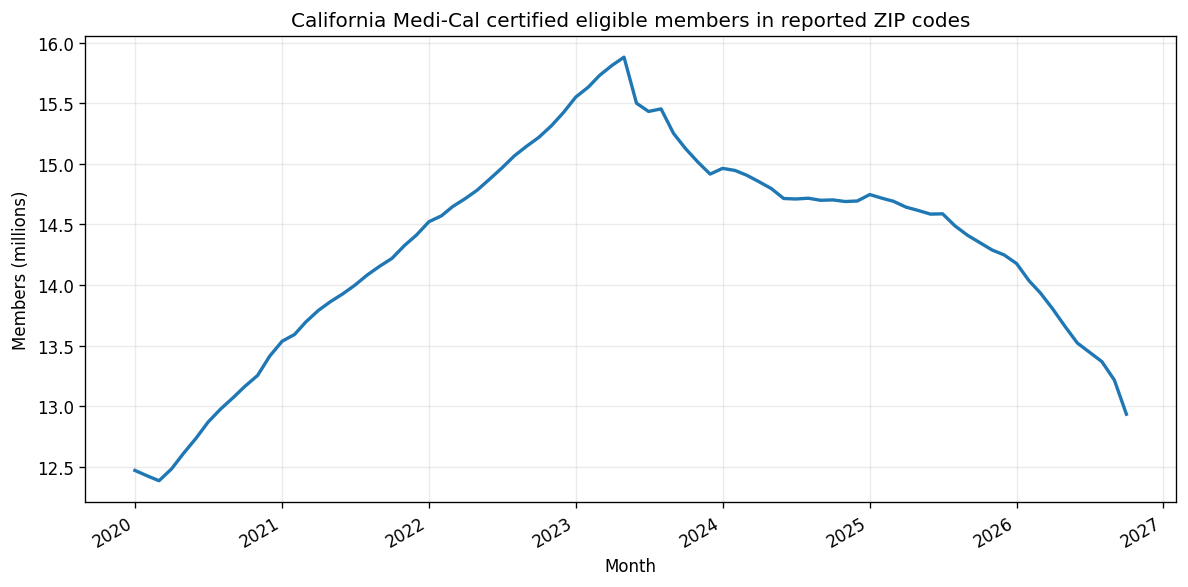

Interpretation: this is all Medi-Cal eligibility in visible ZIPs, not UIS and not IEHP members.


In [ ]:
statewide_monthly = (zip_month.groupby("month", as_index=False)
    .agg(visible_eligible_members=("members", "sum"),
         zip_codes=("zip", "nunique"),
         available_zips=("members", "count")))
statewide_monthly["date"] = pd.to_datetime(statewide_monthly["month"] + "-01")
statewide_monthly["pct_zips_usable"] = 100 * statewide_monthly["available_zips"] / statewide_monthly["zip_codes"]

fig, ax = plt.subplots()
ax.plot(statewide_monthly["date"], statewide_monthly["visible_eligible_members"] / 1e6, linewidth=2)
ax.set(title="California Medi-Cal certified eligible members in reported ZIP codes", xlabel="Month", ylabel="Members (millions)")
ax.grid(alpha=0.25)
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "01_california_enrollment_trend.png", bbox_inches="tight")
plt.show()
print("Interpretation: this is all Medi-Cal eligibility in visible ZIPs, not UIS and not IEHP members.")

## 8. Two-county enrollment charts

These figures are the first **IEHP-focused** results:

1. **Enrollment trend by county:** Are Riverside and San Bernardino moving in the same direction?
2. **County comparison in 2026:** Which county has the larger estimated Medi-Cal population?
3. **Top 15 ZIP codes:** Where is enrollment most concentrated within the two-county region?

All county/region member counts are **residential-address-weighted estimates**. The ZIP ranking uses only the share of each ZIP estimated to fall inside Riverside and San Bernardino, not necessarily the entire ZIP.

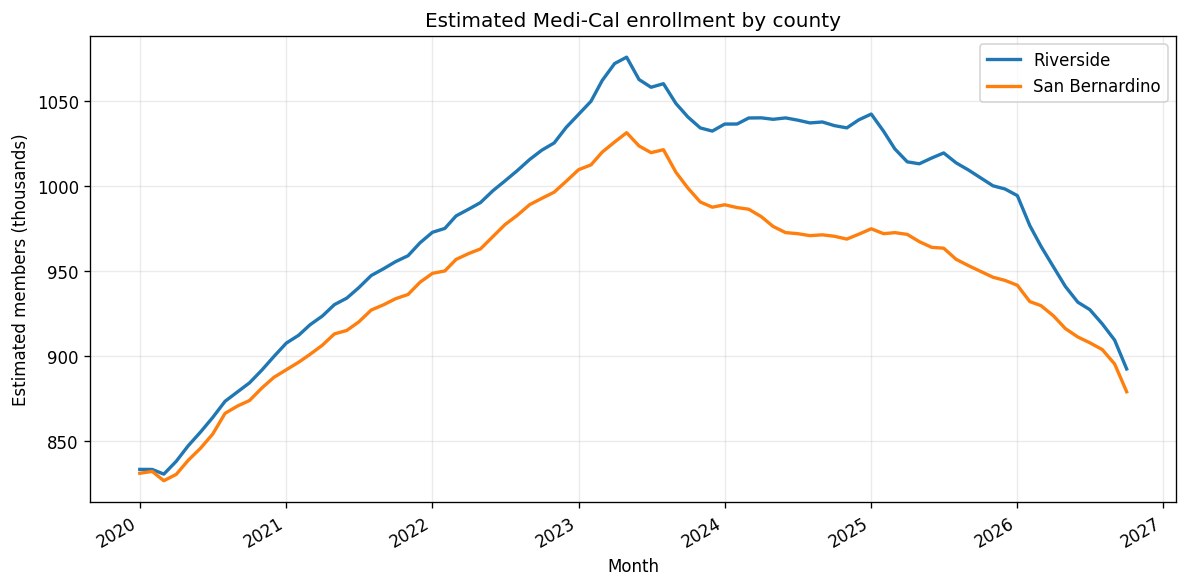

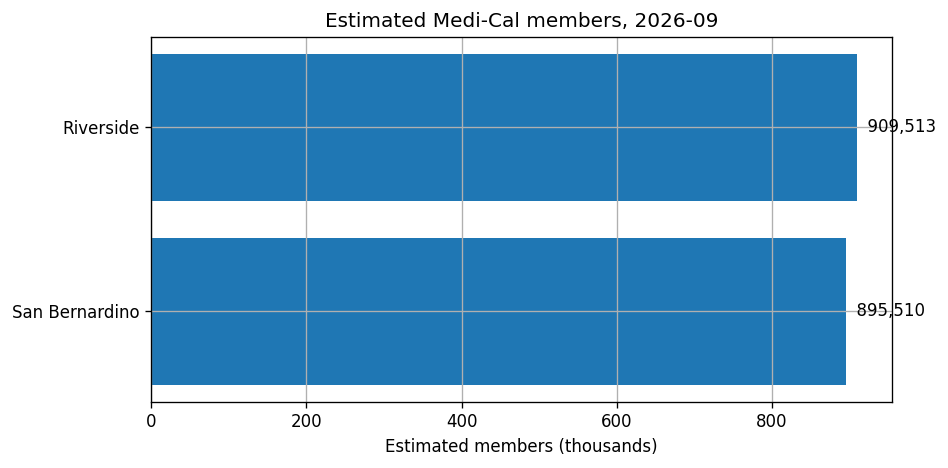

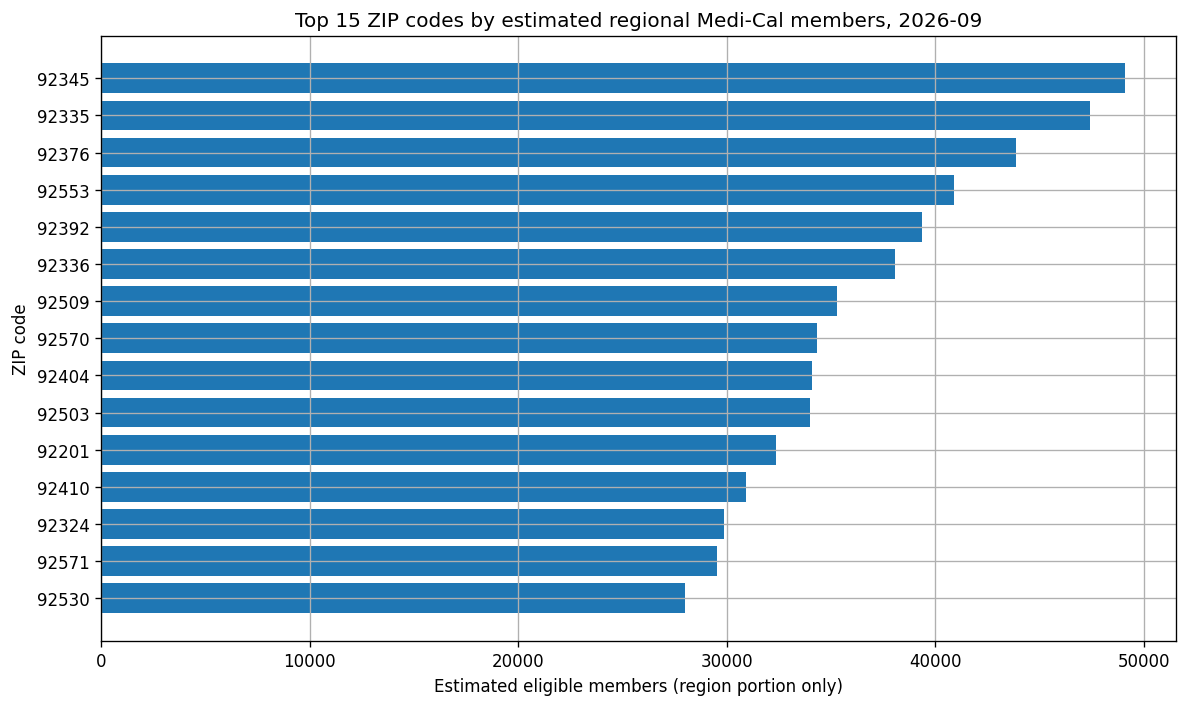

In [ ]:
if have_geography:
    county_plot = county_monthly.pivot(index="month", columns="county", values="estimated_members").sort_index()
    fig, ax = plt.subplots()
    for name in ["Riverside", "San Bernardino"]:
        if name in county_plot.columns:
            ax.plot(pd.to_datetime(county_plot.index + "-01"), county_plot[name] / 1e3, label=name, linewidth=2)
    ax.set(title="Estimated Medi-Cal enrollment by county", xlabel="Month", ylabel="Estimated members (thousands)")
    ax.legend()
    ax.grid(alpha=0.25)
    fig.autofmt_xdate()
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "02_two_county_trends.png", bbox_inches="tight")
    plt.show()

    current_county = county_monthly.loc[county_monthly["month"] == selected_month].sort_values("estimated_members")
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.barh(current_county["county"], current_county["estimated_members"] / 1000)
    ax.set(title=f"Estimated Medi-Cal members, {selected_month}", xlabel="Estimated members (thousands)")
    for idx, (_, row) in enumerate(current_county.iterrows()):
        ax.text(row["estimated_members"] / 1000, idx, f"  {row['estimated_members']:,.0f}", va="center")
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "03_county_comparison.png", bbox_inches="tight")
    plt.show()

    current_zip = region_zip_month.loc[region_zip_month["month"] == selected_month].copy()
    top15 = current_zip.dropna(subset=["estimated_region_members"]).nlargest(15, "estimated_region_members")
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.barh(top15["zip"].iloc[::-1], top15["estimated_region_members"].iloc[::-1])
    ax.set(title=f"Top 15 ZIP codes by estimated regional Medi-Cal members, {selected_month}",
           xlabel="Estimated eligible members (region portion only)", ylabel="ZIP code")
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "04_top_15_zip_codes.png", bbox_inches="tight")
    plt.show()
else:
    print("Skipped county trends, county comparison, and region ZIP ranking: upload the ZIP-to-County crosswalk.")

## 9. Compare with the same month last year

Looking at **September 2026 vs September 2025** (or August vs August) avoids comparing different seasons. The change can show where the *overall Medi-Cal population* is expanding or shrinking.

For each ZIP, calculate:

- **Year-over-year change:** current estimated members minus estimated members in the same month last year.
- **Year-over-year percentage change:** the difference divided by last year's estimate. This is unavailable when the earlier value is missing or zero.
- **Outreach planning score (0–100):** a simple *priority proxy* using **70% enrollment size** and **30% positive absolute year-over-year growth**. High scores mean "large and/or growing Medi-Cal populations worth investigating." **They do not measure UIS exposure, patient risk, provider shortages, or a real count of members transitioning.**

Missing historical values do **not** become zero growth. Their score uses a neutral growth ranking, and the missing comparison remains visible in the output.

ZIP codes with a usable prior-year comparison: 184 / 204


,zip,main_region_county,current_estimated_members,yoy_member_change,yoy_pct_change,outreach_priority_score,year_comparison_available
94,92345,San Bernardino,49099.0,-3192.0,-6.1,83.9,True
85,92335,San Bernardino,47407.0,-3349.0,-6.6,83.5,True
113,92376,San Bernardino,43874.0,-3458.0,-7.3,83.1,True
166,92553,Riverside,40891.0,-5271.0,-11.4,82.7,True
120,92392,San Bernardino,39377.0,-2940.0,-6.9,82.3,True
86,92336,San Bernardino,38095.0,-1459.0,-3.7,82.0,True
146,92509,Riverside,35272.0,-5069.0,-12.6,81.6,True
175,92570,Riverside,34325.0,-4480.0,-11.5,81.2,True
129,92404,San Bernardino,34073.0,-1504.0,-4.2,80.8,True
140,92503,Riverside,33976.0,-4325.0,-11.3,80.5,True


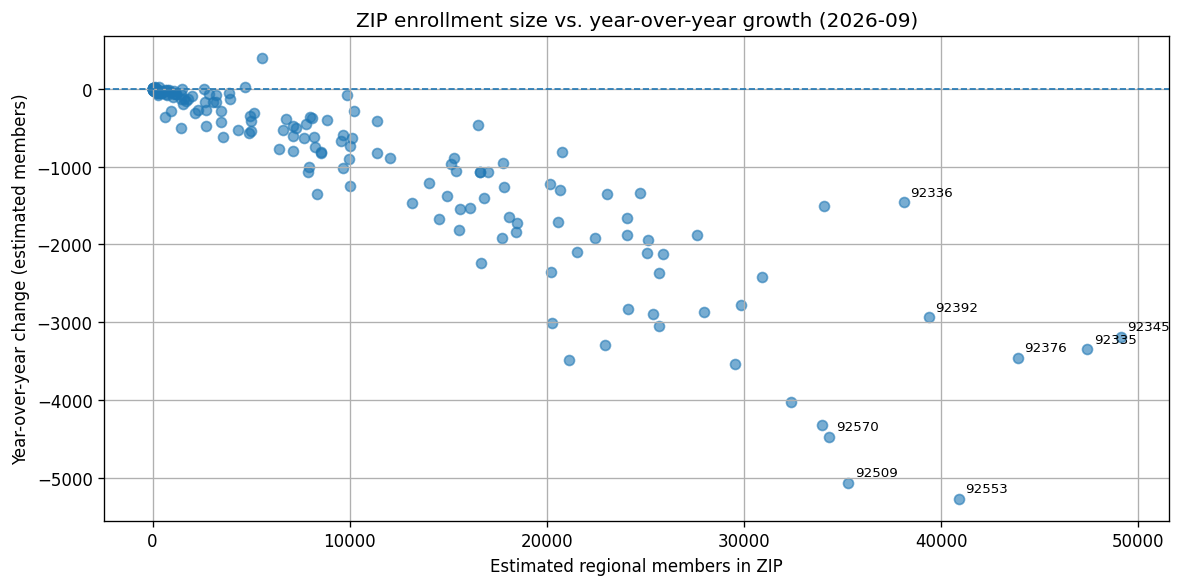

Top 10 ZIP codes account for 22.0% of the region's estimated, usable ZIP-level membership.


In [ ]:
priority_zip = pd.DataFrame()
if have_geography:
    current = (region_zip_month.loc[region_zip_month["month"] == selected_month,
                  ["zip", "estimated_region_members", "main_region_county", "region_res_ratio", "count_method", "month_status"]]
               .rename(columns={"estimated_region_members": "current_estimated_members", "month_status": "current_status"}))
    previous = (region_zip_month.loc[region_zip_month["month"] == previous_year_month,
                   ["zip", "estimated_region_members", "month_status"]]
                .rename(columns={"estimated_region_members": "prior_year_estimated_members", "month_status": "prior_year_status"}))
    priority_zip = current.merge(previous, on="zip", how="left", validate="one_to_one")
    priority_zip["yoy_member_change"] = (priority_zip["current_estimated_members"] -
                                        priority_zip["prior_year_estimated_members"])
    priority_zip["yoy_pct_change"] = np.where(
        priority_zip["prior_year_estimated_members"] > 0,
        100 * priority_zip["yoy_member_change"] / priority_zip["prior_year_estimated_members"], np.nan
    )
    priority_zip["year_comparison_available"] = priority_zip["yoy_member_change"].notna()
    priority_zip["volume_rank"] = priority_zip["current_estimated_members"].rank(pct=True)
    priority_zip["positive_growth_rank"] = (priority_zip["yoy_member_change"].clip(lower=0)).rank(pct=True)
    priority_zip["outreach_priority_score"] = (100 * (0.70 * priority_zip["volume_rank"] +
                                                 0.30 * priority_zip["positive_growth_rank"].fillna(0.50))).round(1)
    priority_zip = priority_zip.sort_values(["outreach_priority_score", "current_estimated_members"], ascending=False)
    print(f"ZIP codes with a usable prior-year comparison: {int(priority_zip['year_comparison_available'].sum()):,} / {len(priority_zip):,}")
    display(priority_zip[["zip", "main_region_county", "current_estimated_members", "yoy_member_change",
                          "yoy_pct_change", "outreach_priority_score", "year_comparison_available"]].head(15).round(1))

    scatter = priority_zip.dropna(subset=["current_estimated_members", "yoy_member_change"])
    if not scatter.empty:
        fig, ax = plt.subplots()
        ax.scatter(scatter["current_estimated_members"], scatter["yoy_member_change"], alpha=0.6)
        ax.axhline(0, linewidth=1, linestyle="--")
        for _, r in scatter.nlargest(8, "outreach_priority_score").iterrows():
            ax.annotate(r["zip"], (r["current_estimated_members"], r["yoy_member_change"]),
                        xytext=(4, 4), textcoords="offset points", fontsize=8)
        ax.set(title=f"ZIP enrollment size vs. year-over-year growth ({selected_month})",
               xlabel="Estimated regional members in ZIP", ylabel="Year-over-year change (estimated members)")
        fig.tight_layout()
        fig.savefig(OUTPUT_DIR / "05_zip_size_vs_growth.png", bbox_inches="tight")
        plt.show()
    else:
        print(f"No comparable ZIP-level counts for {previous_year_month}; growth scatterplot skipped.")

    visible_zips = priority_zip.dropna(subset=["current_estimated_members"]).sort_values("current_estimated_members", ascending=False)
    if not visible_zips.empty and visible_zips["current_estimated_members"].sum() > 0:
        share_top10 = 100 * visible_zips.head(10)["current_estimated_members"].sum() / visible_zips["current_estimated_members"].sum()
        print(f"Top 10 ZIP codes account for {share_top10:.1f}% of the region's estimated, usable ZIP-level membership.")
else:
    print("Skipped ZIP-level priority and year-over-year comparisons: a ZIP-to-County crosswalk is needed.")

## 10. Quality dashboard and decision notes

Before presenting to IEHP, check four things:

1. **Preliminary months:** If the selected month is marked `P`, say the numbers may change.
2. **Suppression:** If many ZIP counts are hidden, reported totals may understate enrollment. Do not invent missing counts.
3. **County approximation:** The crosswalk allocates members using residential address shares, not actual Medi-Cal residency by county.
4. **Policy interpretation:** All counts are for *all Medi-Cal certified eligible members*. Do not label them "UIS members," "IEHP members," "members lost," or "members moving to FFS."

**Recommended next join:** Combine the ZIP-level baseline with **actual IEHP UIS-affected membership by ZIP** (if available and approved) and **FFS-accepting provider counts/capacity**. Then an operational metric becomes possible: `Affected members per available FFS provider`, calculated geographically. Source A alone cannot calculate this.

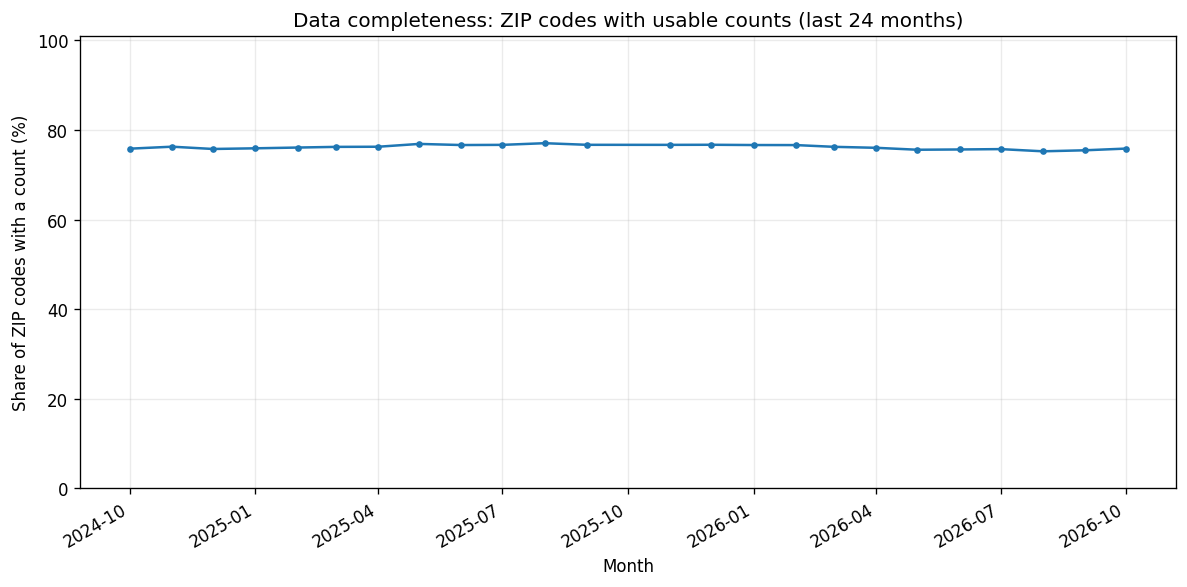

COUNTY DATA COVERAGE (ZIPs with a usable member count)


,county,mapped_zip_codes,usable_zip_counts,zip_count_coverage_pct
158,Riverside,101,96,95.05
159,San Bernardino,112,98,87.50


Present these data as a geographic baseline. UIS exposure and provider access need other sources.


In [ ]:
fig, ax = plt.subplots()
q = monthly_quality.tail(24).copy()
ax.plot(pd.to_datetime(q["month"] + "-01"), q["pct_zips_usable"], marker="o", markersize=3)
ax.set(title="Data completeness: ZIP codes with usable counts (last 24 months)",
       xlabel="Month", ylabel="Share of ZIP codes with a count (%)", ylim=(0, 101))
ax.grid(alpha=0.25)
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "06_zip_count_completeness.png", bbox_inches="tight")
plt.show()

if have_geography:
    s = county_monthly.loc[county_monthly["month"] == selected_month,
                           ["county", "mapped_zip_codes", "usable_zip_counts", "zip_count_coverage_pct"]]
    print("COUNTY DATA COVERAGE (ZIPs with a usable member count)")
    display(s)
print("Present these data as a geographic baseline. UIS exposure and provider access need other sources.")

## 11. Save analysis files and charts

**Files produced:**

| Filename | Use |
|---|---|
| `cleaned_zip_month.csv` | One row per valid ZIP per month, with member count and calculation method |
| `monthly_data_quality.csv` | Completeness checks across all months |
| `statewide_monthly_visible_enrollment.csv` | California context and trend |
| `estimated_county_monthly.csv` | Riverside and San Bernardino estimates (when crosswalk present) |
| `estimated_region_monthly.csv` | Combined two-county estimates (when crosswalk present) |
| `zip_outreach_priorities_2026-XX.csv` | Ranked ZIP list with prior-year changes and score (when crosswalk present) |
| `01_...png` through `06_...png` | Graphs for a dashboard or presentation |
| `analysis_notes.txt` | Reporting cautions and definitions |

Every output with the word **estimated** uses HUD residential address proportions. Do not add monthly totals together and call the result "unique people"; these are repeated monthly snapshots.

In [ ]:
zip_month.to_csv(OUTPUT_DIR / "cleaned_zip_month.csv", index=False)
monthly_quality.to_csv(OUTPUT_DIR / "monthly_data_quality.csv", index=False)
statewide_monthly.to_csv(OUTPUT_DIR / "statewide_monthly_visible_enrollment.csv", index=False)
report_summary.to_csv(OUTPUT_DIR / "selected_month_quality_summary.csv", index=False)
if have_geography:
    county_monthly.to_csv(OUTPUT_DIR / "estimated_county_monthly.csv", index=False)
    region_monthly.to_csv(OUTPUT_DIR / "estimated_region_monthly.csv", index=False)
    priority_zip.to_csv(OUTPUT_DIR / f"zip_outreach_priorities_{selected_month}.csv", index=False)

notes = f"""IEHP SOURCE A ANALYSIS — {selected_month}

SOURCE: California DHCS — certified eligible Medi-Cal counts by ZIP and sex, 2020–latest.
COMPARISON: {previous_year_month} (same calendar month, previous year).
CROSSWALK: {crosswalk_path.name if have_geography else 'Not provided; region analyses skipped'}.

DEFINITIONS:
- Raw file has Female, Male, and Total rows. Never sum all three.
- Primary count = Female + Male. If one is missing, use published Total if available.
- A conflict between published Total and sex sum is excluded until reviewed.
- Missing/suppressed counts are unknown; they are not zero.
- Unknown/invalid ZIP codes are excluded from ZIP-level and regional figures.
- Counts are monthly certified eligible people; summing over months does not yield unique people.
- Preliminary (P) months can be revised; final (F) months are considered complete by DHCS.
- County figures use HUD ZIP-to-County RES_RATIO (residential address share) and are estimates.
- The outreach priority score is 70% ZIP enrollment percentile + 30% positive year-over-year
  absolute growth percentile. It is a planning proxy, NOT a validated patient-risk measure.

IMPORTANT LIMITATIONS:
This dataset contains all Medi-Cal certified eligible members. It has no immigration status,
IEHP plan membership, managed-care/FFS delivery system, provider capacity, utilization, or
individual-level records. It cannot identify how many people will transition in January 2027.

SUGGESTED NEXT STEP:
Join appropriately governed IEHP UIS membership by ZIP to provider FFS acceptance/capacity.
Then calculate affected members per FFS-accepting provider and geographic coverage.

OFFICIAL LINKS:
https://data.ca.gov/@california-department-of-health-care-services/medi-cal-certified-eligible-counts-by-month-of-eligibility-zip-code-and-sex
https://www.huduser.gov/portal/datasets/usps_crosswalk.html
https://www.dhcs.ca.gov/providers-partners/medi-cal-fee-for-service-transition/
"""
(OUTPUT_DIR / "analysis_notes.txt").write_text(notes, encoding="utf-8")
archive = OUTPUT_DIR.parent / f"IEHP_Source_A_Analysis_{selected_month}.zip"
with zipfile.ZipFile(archive, "w", zipfile.ZIP_DEFLATED) as bundle:
    for path in sorted(OUTPUT_DIR.iterdir()):
        if path.is_file():
            bundle.write(path, arcname=path.name)
print(f"Saved {len(list(OUTPUT_DIR.iterdir()))} analysis files.")
print("Bundle location:", archive)
if IN_COLAB:
    from google.colab import files
    files.download(str(archive))

Saved 14 analysis files.
Bundle location: /content/IEHP_Source_A_Analysis_2026-09.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 12. Simple explanation for an IEHP presentation

**Finding:** Source A shows *where overall Medi-Cal enrollment is concentrated* and how the counts changed leading up to the scheduled January 2027 delivery-system transition.

**Why leadership should care:** ZIP codes with large or growing Medi-Cal populations are sensible places to look first when planning outreach and evaluating whether the local Fee-for-Service provider network can absorb demand.

**What we still need:** IEHP's actual UIS-affected member counts by ZIP and data on which providers accept FFS. Without those, we cannot conclude which ZIP codes have the highest *transition risk*.

**Do not interpret** county estimates as exact official county totals or the outreach priority score as a prediction of negative health outcomes.

5 Key Takeaways
1. Approximately 1.81 million Medi-Cal members are estimated across the two counties. Riverside accounts for approximately 910,000 and San Bernardino for 896,000 as of September 2026, demonstrating the scale of the regional population that must be considered in transition planning.
2. Medi-Cal enrollment is declining across both counties. Enrollment peaked around 2023 and has trended downward through 2026. All 15 highest-priority ZIP codes also experienced year-over-year enrollment declines, highlighting changing healthcare demand and the need to understand the causes.
3. Medi-Cal enrollment is geographically concentrated. The top 10 ZIP codes account for approximately 22% of the region's estimated enrollment. ZIP codes 92345, 92335, and 92376 have some of the largest populations, providing clear geographic starting points for further investigation and outreach planning.
4. Geographic analysis provides a foundation for targeted intervention. ZIP-level enrollment trends and population rankings can help IEHP prioritize where to investigate provider availability, healthcare accessibility, and potential service gaps rather than applying a uniform approach across both counties.
5. Additional data is necessary to identify actual transition risks. Current data represents all Medi-Cal eligible members, not specifically IEHP members or those with Unsatisfactory Immigration Status (UIS). September 2026 data is preliminary, and some ZIP counts are suppressed. Actual transition exposure and healthcare access risks cannot yet be determined.
Recommended Next Actions
- Identify affected populations: Integrate IEHP-specific UIS enrollment data by ZIP code to determine the actual number and geographic distribution of members transitioning to FFS.
- Evaluate provider accessibility: Combine affected-member data with FFS-accepting provider locations, specialties, availability, and capacity to identify potential healthcare access gaps.
- Develop a geographic risk score: Create a metric such as Affected Members per Available FFS Provider to rank ZIP codes by potential provider demand and accessibility challenges.
- Build an interactive monitoring dashboard: Visualize affected populations, provider availability, high-priority ZIP codes, and transition readiness indicators to support IEHP leadership decisions.
- Pilot targeted interventions: Select high-risk ZIP codes for proactive member communication, provider coordination, and continuity-of-care support. Measure effectiveness before expanding to other regions.